# Aplicación 4 — Texto: análisis de sentimiento con un Transformer desde cero

**Objetivo:** entender por qué el **orden** y el **contexto** importan en lenguaje natural, y cómo el mecanismo de
**auto-atención** del Transformer (Vaswani et al., 2017) los captura.

Construimos un pequeño corpus de reseñas en español con dos fenómenos lingüísticos que confunden a los modelos
simples:

- **Negación:** *"la comida **no** fue excelente"* es negativa aunque contenga "excelente".
- **Contraste con "pero":** *"el servicio fue terrible **pero** la comida fue espectacular"* es positiva: manda la
  segunda cláusula. Si invertimos el orden, cambia la etiqueta, aunque las palabras sean exactamente las mismas.

Compararemos:
1. Un modelo de **bolsa de palabras** (promedio de *embeddings* + capa lineal), que ignora el orden.
2. Un **Transformer encoder** implementado bloque a bloque, cuyas atenciones podemos visualizar.

> En la introducción a PyTorch ya entrenamos un modelo generativo de caracteres (Shakespeare). Aquí trabajamos la
> otra gran familia de tareas de NLP: **clasificación de secuencias**.

In [1]:
import math
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import Counter

random.seed(0)
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. Un corpus de reseñas con estructura

Generamos frases a partir de plantillas. La etiqueta se determina con reglas lingüísticas explícitas, así sabemos
exactamente qué debe aprender el modelo.

In [2]:
ASPECTS = ["la comida", "el servicio", "la película", "el hotel", "la música", "el precio", "la atención",
           "el producto", "la habitación", "el envío", "la app", "el libro", "la trama", "el personal"]
VERBS = ["es", "fue", "estuvo", "me pareció", "resultó", "era"]
POS = ["excelente", "increíble", "genial", "impecable", "espectacular", "agradable", "maravilloso",
       "fantástico", "estupendo", "brillante"]
NEG = ["terrible", "horrible", "lamentable", "desagradable", "insoportable", "pésimo", "decepcionante",
       "mediocre", "aburrido", "deficiente"]
INTENS = ["", "", "muy ", "bastante ", "realmente ", "algo "]
PREFIX = ["", "", "", "sinceramente ", "en general ", "la verdad ", "para mí "]

def agree(adj, aspect):
    # concordancia de género: "el libro fue aburrido" / "la trama fue aburrida"
    return adj[:-1] + "a" if aspect.startswith("la ") and adj.endswith("o") else adj

def clause(avoid=None):
    positive = random.random() < 0.5
    aspect = random.choice([a for a in ASPECTS if a != avoid])
    adj = agree(random.choice(POS if positive else NEG), aspect)
    negated = random.random() < 0.35
    verb = ("no " if negated else "") + random.choice(VERBS)
    text = f"{aspect} {verb} {random.choice(INTENS)}{adj}"
    return text, int(positive != negated), aspect    # la negación invierte la polaridad

def make_review():
    r = random.random()
    if r < 0.4:                                       # una sola cláusula
        text, label, _ = clause()
    elif r < 0.8:                                     # "A pero B" → manda B
        a, _, asp = clause()
        b, label, _ = clause(avoid=asp)
        text = f"{a} pero {b}"
    else:                                             # "A y B" con la misma polaridad
        a, label, asp = clause()
        b, lb, _ = clause(avoid=asp)
        while lb != label:
            b, lb, _ = clause(avoid=asp)
        text = f"{a} y {b}"
    return random.choice(PREFIX) + text, label

data = [make_review() for _ in range(30000)]
for text, label in data[:8]:
    print("😊" if label else "😠", text)
print("proporción positiva:", sum(l for _, l in data) / len(data))

😊 la atención no resultó bastante terrible y el personal estuvo realmente espectacular
😠 la verdad la trama estuvo realmente increíble pero el personal estuvo deficiente
😠 el precio estuvo bastante mediocre
😠 para mí la habitación resultó muy mediocre pero el envío no me pareció algo excelente
😊 el envío estuvo mediocre pero la trama no resultó horrible
😠 en general la habitación no estuvo realmente fantástica y el precio no resultó realmente estupendo
😠 la trama no fue muy maravillosa
😊 para mí el envío es algo espectacular
proporción positiva: 0.49906666666666666


## 2. Tokenización y vocabulario

Usamos tokenización por palabras (en modelos grandes se usan *subwords* como BPE). Reservamos tokens especiales:
`<pad>` para rellenar secuencias cortas, `<unk>` para palabras desconocidas y `<cls>`, cuyo vector final usaremos
como resumen de la frase (igual que en BERT).

In [3]:
def tokenize(text):
    return text.lower().split()

counts = Counter(tok for text, _ in data for tok in tokenize(text))
itos = ["<pad>", "<unk>", "<cls>"] + sorted(counts)
stoi = {w: i for i, w in enumerate(itos)}
PAD, UNK, CLS = 0, 1, 2
MAX_LEN = max(len(tokenize(t)) for t, _ in data) + 1
print("vocabulario:", len(itos), "| longitud máxima:", MAX_LEN)

def encode(text):
    ids = [CLS] + [stoi.get(tok, UNK) for tok in tokenize(text)]
    return ids + [PAD] * (MAX_LEN - len(ids))

X = torch.tensor([encode(t) for t, _ in data])
Y = torch.tensor([l for _, l in data])
n_tr, n_va = 24000, 27000
X_tr, Y_tr, X_va, Y_va, X_te, Y_te = X[:n_tr], Y[:n_tr], X[n_tr:n_va], Y[n_tr:n_va], X[n_va:], Y[n_va:]
print(data[0][0], "→", X[0].tolist())

vocabulario: 64 | longitud máxima: 18


la atención no resultó bastante terrible y el personal estuvo realmente espectacular → [2, 36, 8, 46, 57, 9, 60, 63, 15, 51, 23, 56, 20, 0, 0, 0, 0, 0]


## 3. Modelo base: bolsa de palabras

Promedia los *embeddings* de las palabras (ignorando el relleno) y aplica una capa lineal. Por construcción es
**invariante al orden**: para este modelo *"A pero B"* y *"B pero A"* son la misma entrada.

In [4]:
class BagOfWords(nn.Module):
    def __init__(self, vocab, dim=64):
        super().__init__()
        self.emb = nn.Embedding(vocab, dim, padding_idx=PAD)
        self.out = nn.Linear(dim, 2)
    def forward(self, x):
        mask = (x != PAD).unsqueeze(-1).float()
        h = (self.emb(x) * mask).sum(1) / mask.sum(1)
        return self.out(h)

def train(model, epochs, lr):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * math.ceil(n_tr / 128)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n_tr)
        for k in range(0, n_tr, 128):
            idx = perm[k:k + 128]
            loss = F.cross_entropy(model(X_tr[idx].to(device)), Y_tr[idx].to(device))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
        print(f"época {epoch + 1} | loss {loss.item():.3f} | acc val {accuracy(model, X_va, Y_va):.3f}")
    return model

def accuracy(model, Xs, Ys):
    model.eval()
    with torch.no_grad():
        return (model(Xs.to(device)).argmax(1).cpu() == Ys).float().mean().item()

bow = train(BagOfWords(len(itos)), epochs=6, lr=5e-3)
print(f"\nBolsa de palabras — exactitud en test: {accuracy(bow, X_te, Y_te):.3f}")

época 1 | loss 0.652 | acc val 0.599


época 2 | loss 0.653 | acc val 0.626
época 3 | loss 0.626 | acc val 0.617


época 4 | loss 0.611 | acc val 0.618
época 5 | loss 0.685 | acc val 0.618


época 6 | loss 0.620 | acc val 0.619

Bolsa de palabras — exactitud en test: 0.627


## 4. Transformer encoder, bloque a bloque

Cada bloque tiene dos sub-capas, ambas con conexión residual y *LayerNorm* (variante *pre-norm*):

1. **Auto-atención multi-cabeza.** Cada token produce una *query* $Q$, una *key* $K$ y un *value* $V$; el
   token $i$ combina los *values* de todos los tokens ponderados por
   $\mathrm{softmax}\!\left(\frac{Q_i K^\top}{\sqrt{d_k}}\right)$. Así, "excelente" puede "mirar" a un "no" que
   está antes, y `<cls>` puede mirar a la cláusula después de "pero".
2. **Red feed-forward** aplicada a cada posición por separado.

Como la atención por sí sola no sabe en qué posición está cada palabra, sumamos un **embedding posicional**.
Guardamos las matrices de atención para visualizarlas después.

In [5]:
class SelfAttention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.heads, self.d_k = heads, dim // heads
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x, pad_mask):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.heads, self.d_k).permute(2, 0, 3, 1, 4)  # 3 × [B, H, T, d_k]
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d_k)                               # [B, H, T, T]
        scores = scores.masked_fill(pad_mask[:, None, None, :], float("-inf"))               # no atender al relleno
        attn = scores.softmax(dim=-1)
        out = (attn @ v).transpose(1, 2).reshape(B, T, D)
        return self.proj(out), attn

class TransformerBlock(nn.Module):
    def __init__(self, dim, heads, dropout=0.1):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = SelfAttention(dim, heads)
        self.ff = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(), nn.Linear(4 * dim, dim))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, pad_mask):
        a, weights = self.attn(self.norm1(x), pad_mask)
        x = x + self.drop(a)
        x = x + self.drop(self.ff(self.norm2(x)))
        return x, weights

class SentimentTransformer(nn.Module):
    def __init__(self, vocab, max_len, dim=64, heads=4, layers=2):
        super().__init__()
        self.tok = nn.Embedding(vocab, dim, padding_idx=PAD)
        self.pos = nn.Embedding(max_len, dim)
        self.blocks = nn.ModuleList([TransformerBlock(dim, heads) for _ in range(layers)])
        self.norm = nn.LayerNorm(dim)
        self.out = nn.Linear(dim, 2)
        self.attentions = []

    def forward(self, x):
        pad_mask = x == PAD
        h = self.tok(x) + self.pos(torch.arange(x.shape[1], device=x.device))
        self.attentions = []
        for block in self.blocks:
            h, w = block(h, pad_mask)
            self.attentions.append(w.detach())
        return self.out(self.norm(h[:, 0]))          # el vector de <cls> resume la frase

transformer = SentimentTransformer(len(itos), MAX_LEN)
print(f"Parámetros: {sum(p.numel() for p in transformer.parameters()):,}")
transformer = train(transformer, epochs=8, lr=2e-3)
print(f"\nTransformer — exactitud en test: {accuracy(transformer, X_te, Y_te):.3f}")

Parámetros: 105,474


época 1 | loss 0.375 | acc val 0.765


época 2 | loss 0.001 | acc val 0.999


época 3 | loss 0.000 | acc val 1.000


época 4 | loss 0.000 | acc val 1.000


época 5 | loss 0.000 | acc val 1.000


época 6 | loss 0.000 | acc val 1.000


época 7 | loss 0.000 | acc val 1.000


época 8 | loss 0.000 | acc val 1.000

Transformer — exactitud en test: 1.000


## 5. ¿Dónde falla cada modelo?

Separamos el conjunto de prueba por tipo de frase.

In [6]:
test_texts = [t for t, _ in data[n_va:]]
groups = {
    "simple, sin negación": lambda t: " pero " not in t and " y " not in t and " no " not in f" {t} ",
    "simple, con negación": lambda t: " pero " not in t and " y " not in t and " no " in f" {t} ",
    "contraste con 'pero'": lambda t: " pero " in t,
    "conjunción con 'y'": lambda t: " y " in t,
}
print(f"{'tipo de frase':24s} {'n':>5s} {'BoW':>7s} {'Transformer':>12s}")
for name, cond in groups.items():
    idx = torch.tensor([i for i, t in enumerate(test_texts) if cond(t)])
    print(f"{name:24s} {len(idx):5d} {accuracy(bow, X_te[idx], Y_te[idx]):7.3f} "
          f"{accuracy(transformer, X_te[idx], Y_te[idx]):12.3f}")

tipo de frase                n     BoW  Transformer
simple, sin negación       814   1.000        1.000
simple, con negación       407   0.000        1.000
contraste con 'pero'      1178   0.571        1.000
conjunción con 'y'         601   0.656        1.000


La bolsa de palabras acierta en las frases simples sin negación, pero **falla sistemáticamente con la negación**:
su puntuación es una suma de contribuciones independientes de cada palabra, así que no puede expresar "positivo,
salvo que haya un *no* antes". Con los contrastes queda cerca del azar porque **no ve el orden**. El Transformer
resuelve todos los casos.

Ojo: aquí el Transformer llega a ~100 % porque el corpus sigue reglas exactas. Con reseñas reales (ironía,
vocabulario abierto, etiquetas ruidosas) los buenos modelos están típicamente entre 85 % y 95 %.

## 6. Visualizando la atención

Mostramos cuánto atiende el token `<cls>` a cada palabra en la última capa (promedio de las cabezas). Es una
herramienta de interpretación útil, aunque hay que tomarla con cautela: la atención no es una explicación causal
completa del modelo.

😊 P(positivo) = 1.000 | el servicio fue terrible pero la comida fue espectacular
😠 P(positivo) = 0.000 | la comida fue espectacular pero el servicio fue terrible
😊 P(positivo) = 1.000 | la película no fue aburrida
😠 P(positivo) = 0.000 | sinceramente el hotel no me pareció muy agradable


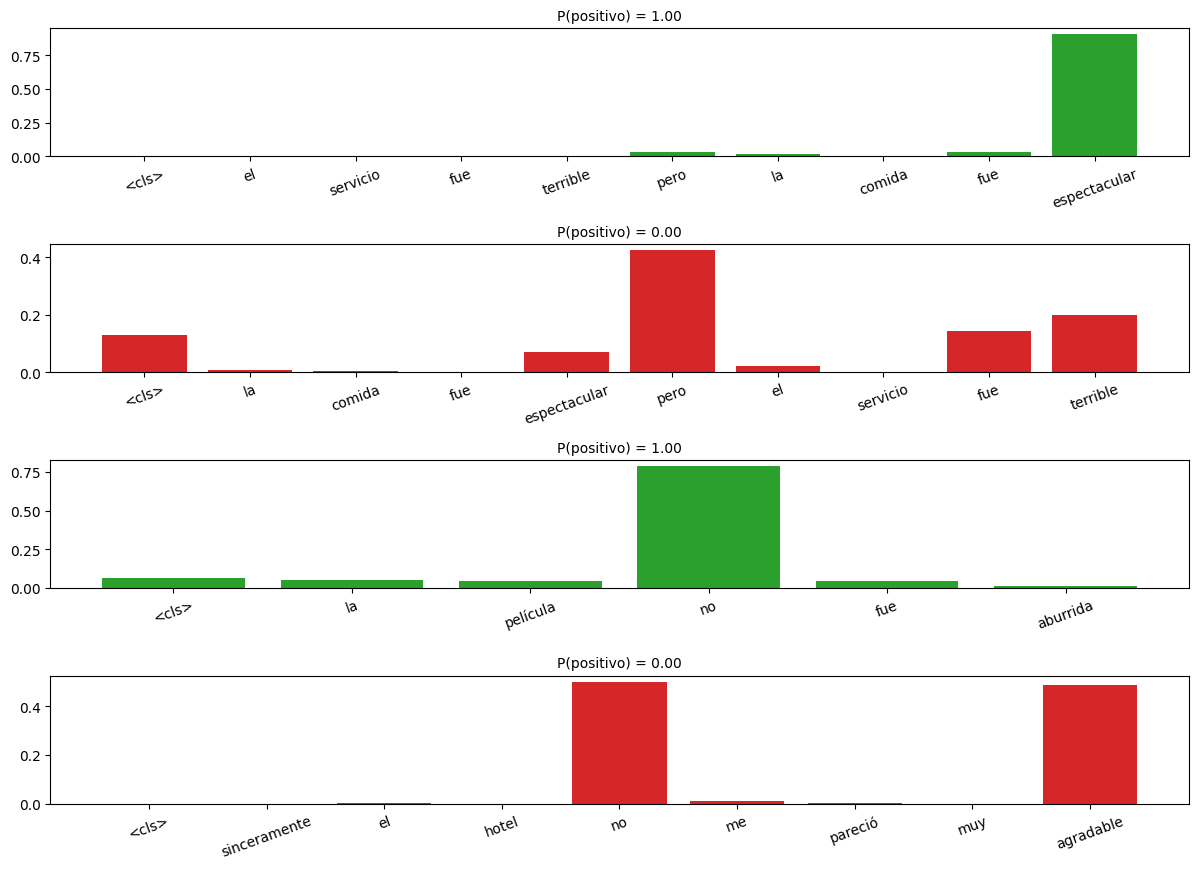

In [7]:
def classify(text, show=True):
    x = torch.tensor([encode(text)]).to(device)
    transformer.eval()
    with torch.no_grad():
        prob = F.softmax(transformer(x), dim=1)[0, 1].item()
    if show:
        print(f"{'😊' if prob > 0.5 else '😠'} P(positivo) = {prob:.3f} | {text}")
    return prob

examples = [
    "el servicio fue terrible pero la comida fue espectacular",
    "la comida fue espectacular pero el servicio fue terrible",
    "la película no fue aburrida",
    "sinceramente el hotel no me pareció muy agradable",
]
fig, axes = plt.subplots(len(examples), 1, figsize=(12, 2.2 * len(examples)))
for ax, text in zip(axes, examples):
    p = classify(text)
    tokens = ["<cls>"] + tokenize(text)
    w = transformer.attentions[-1][0].mean(0)[0, :len(tokens)].cpu()    # fila de <cls>, promedio de cabezas
    ax.bar(range(len(tokens)), w, color=["C2" if p > 0.5 else "C3"])
    ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=20)
    ax.set_title(f"P(positivo) = {p:.2f}", fontsize=10)
plt.tight_layout(); plt.show()

😠 P(positivo) = 0.000 | la app era bastante genial pero el envío no fue impecable


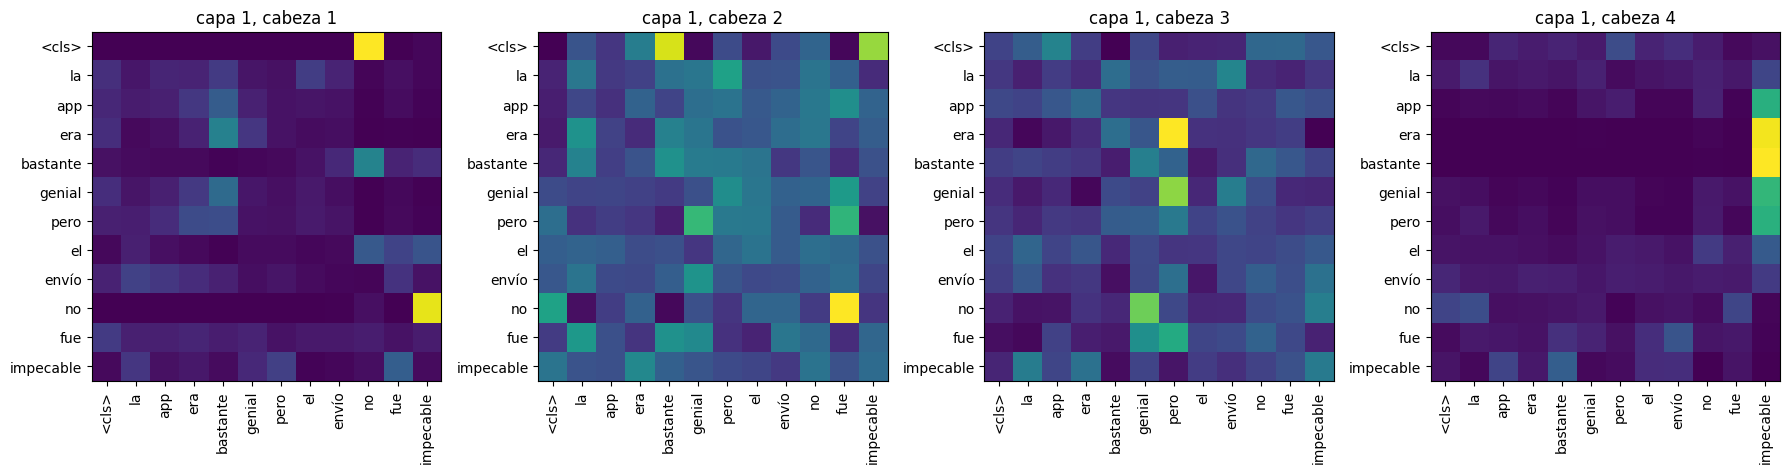

In [8]:
text = "la app era bastante genial pero el envío no fue impecable"
classify(text)
tokens = ["<cls>"] + tokenize(text)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for h, ax in enumerate(axes):
    w = transformer.attentions[0][0, h, :len(tokens), :len(tokens)].cpu()
    ax.imshow(w, cmap="viridis")
    ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=90)
    ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens)
    ax.set_title(f"capa 1, cabeza {h + 1}")
plt.tight_layout(); plt.show()

Cada cabeza aprende patrones distintos: algunas conectan adjetivos con el "no" que los precede, otras
distinguen las palabras antes y después de "pero".

## 7. Prueba tus propias frases

Sólo funcionan con palabras del vocabulario; las demás se convierten en `<unk>`.

In [9]:
for t in ["el libro me pareció brillante",
          "el libro no me pareció brillante",
          "la trama era aburrida pero el personal fue fantástico y la música fue estupenda",
          "en general la habitación no estuvo mediocre"]:
    classify(t)

😊 P(positivo) = 1.000 | el libro me pareció brillante
😠 P(positivo) = 0.000 | el libro no me pareció brillante
😊 P(positivo) = 1.000 | la trama era aburrida pero el personal fue fantástico y la música fue estupenda
😊 P(positivo) = 1.000 | en general la habitación no estuvo mediocre


## 8. Siguientes pasos: datos reales y modelos preentrenados

- Datasets reales en español: reseñas de Amazon (`amazon_reviews_multi`), tuits de **TASS**, o **MuchoCine**.
  Con la librería `datasets` de Hugging Face: `load_dataset("...")`.
- En la práctica se parte de un modelo preentrenado (BETO, RoBERTa-BNE, XLM-RoBERTa) y se hace *fine-tuning*.
  La arquitectura es la misma que escribimos aquí, sólo que mucho más grande y entrenada en millones de textos:
  ```python
  from transformers import AutoTokenizer, AutoModelForSequenceClassification
  name = "dccuchile/bert-base-spanish-wwm-cased"
  tok = AutoTokenizer.from_pretrained(name)
  model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
  ```

**Ejercicios**
1. Quita el embedding posicional del Transformer. ¿Qué tipo de frases empiezan a fallar y por qué?
2. Agrega el conector "aunque" (*"aunque A, B"* → manda B) y la doble negación.
3. Reemplaza la bolsa de palabras por una LSTM bidireccional y compárala con el Transformer.
4. Usa una sola capa y una sola cabeza. ¿Sigue resolviendo los contrastes con negación dentro de la segunda cláusula?